# Potomac River at Little Falls — USGS-01646500

This gauge watches the Potomac River at Little Falls, right where the river leaves Maryland and enters Washington, DC. Since March 1930, the USGS has measured how much water flows past this spot every single day. Everything that happens in the 11,560 square miles of land that drains into the river ends up in this one number.

It is one of the most watched gauges in the country, for a simple reason: **the water that passes Little Falls is the water the capital region drinks.**

Important facts:
* **Drinking water.** DC and the surrounding suburbs take about three-quarters of their water from the Potomac. The pumping station next to the gauge is part of the Washington Aqueduct. Below the gauge the river is "managed", because pipes pull water out of it, so Little Falls is the last honest look at how much water the basin actually produced.
* **Drought.** When the number here gets too low, the region starts releasing water from backup reservoirs and asks people to water their lawns less. The 2022 drought showed this: flows fell to near-record lows and restrictions followed.
* **Floods.** The same gauge is the early warning for big storms and ice jams. The huge flood of March 1936 (about as big as the 1889 one, which happened before the daily record begins) came through right here.

## Install and imports

In [ ]:
%pip install dataretrieval # USGS package for data retrieval
%pip install geopandas
%pip install statsmodels
%pip install --index-url https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple/ rhis-ts==0.1.0

In [1]:
from rhis_ts import Rhis
from statsmodels.tsa.seasonal import seasonal_decompose
from dataretrieval import waterdata # https://waterdata.usgs.gov/?utm_source=chatgpt.com
from helpers import build_rhis_evol_df, build_repr_df
from plotting import plot_rhis_evolution # Helper function to plot the representative series along with their p-value evolutions

## Getting the data

The daily discharge record runs from March 1930 to today. Let's pull it and take a first look at how this river behaves.

In [2]:
# Get daily streamflow data (returns DataFrame and metadata)
df, metadata = waterdata.get_daily(
    monitoring_location_id="USGS-01646500",
    parameter_code="00060",  # Discharge
    time="1930-01-01/2026-10-28",
)

df.info()

Retrieving: daily · 1 page · 35,305 rows


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 35305 entries, 0 to 35304
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   geometry                35305 non-null  geometry           
 1   time_series_id          35305 non-null  str                
 2   monitoring_location_id  35305 non-null  str                
 3   parameter_code          35305 non-null  str                
 4   statistic_id            35305 non-null  str                
 5   time                    35305 non-null  datetime64[us]     
 6   value                   35305 non-null  float64            
 7   unit_of_measure         35305 non-null  str                
 8   approval_status         35305 non-null  str                
 9   qualifier               345 non-null    object             
 10  last_modified           35305 non-null  datetime64[us, UTC]
 11  daily_id                35305 non

In [3]:
df = df.set_index('time') # Set time as the dataframe index, so Rhis doesn't treat it as data to be analyzed
target_df = df[['value']].rename(columns={'value': 'flow'}).copy()
target_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 35305 entries, 1930-03-01 to 2026-10-27
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   flow    35305 non-null  float64
dtypes: float64(1)
memory usage: 551.6 KB


## Exploring

<Axes: title={'center': 'Daily Flows — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

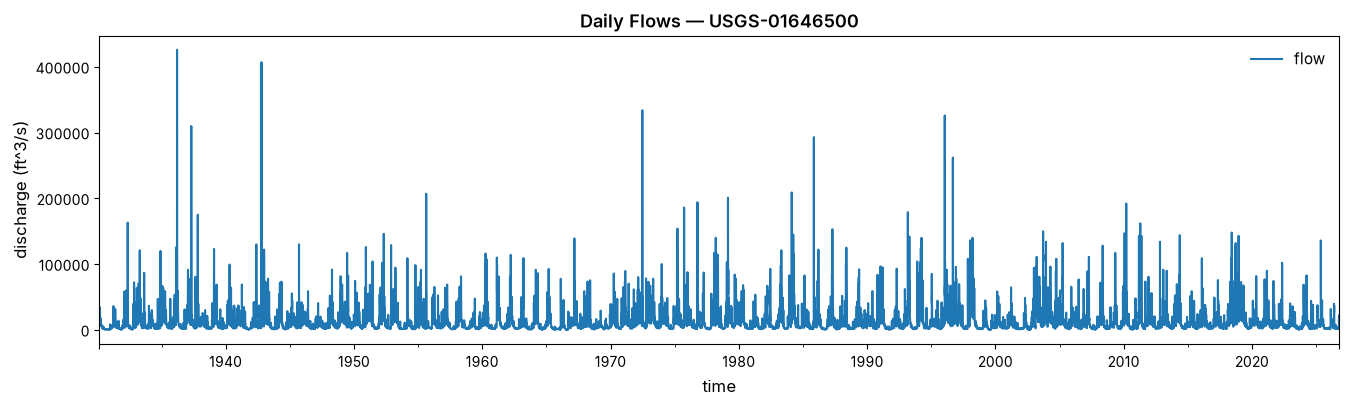

In [4]:
target_df.plot(
    figsize=(16, 4),
    title="Daily Flows — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

As expected, the flows show seasonal variations. No visible trends are present. Some outliers are present. The first thing to do, in order to find the longest and most recent stretch that is compliant with the basic assumptions for frequency analysis (randomness, homogeneity, independence, and stationarity), is to handle the expected persistence/dependence of daily flows — usually determined by the flows from previous days — and seasonality.

In [5]:
monthly_df = target_df.resample("MS").mean().reset_index().set_index('time') # Persistence tends to disappear with aggregations to larger scales such as monthly and annual
monthly_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1160 entries, 1930-03-01 to 2026-10-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   flow    1160 non-null   float64
dtypes: float64(1)
memory usage: 18.1 KB


<Axes: title={'center': 'Monthly Flows — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

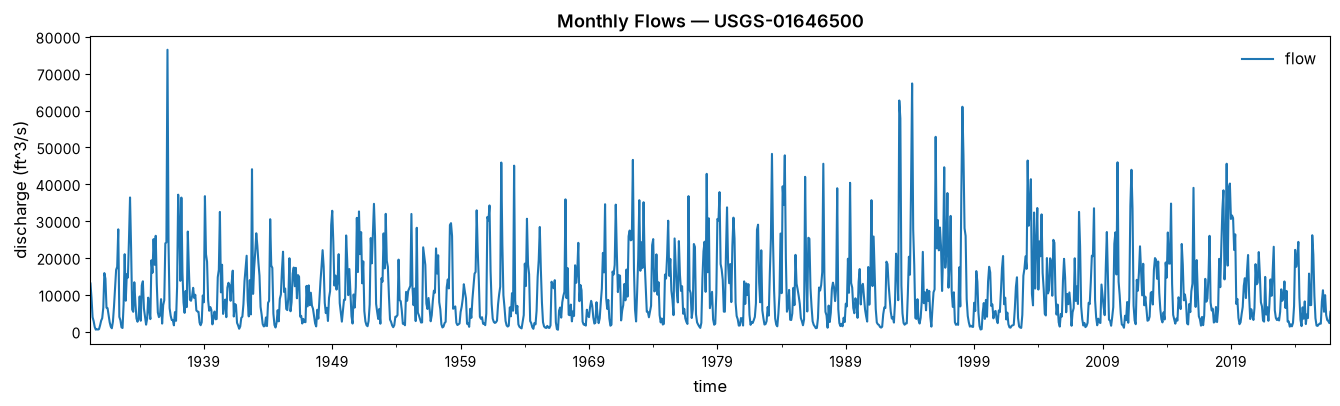

In [6]:
monthly_df.plot(
    figsize=(16, 4),
    title="Monthly Flows — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

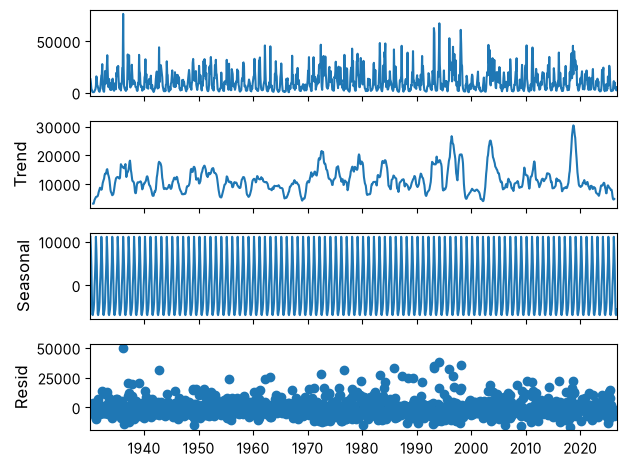

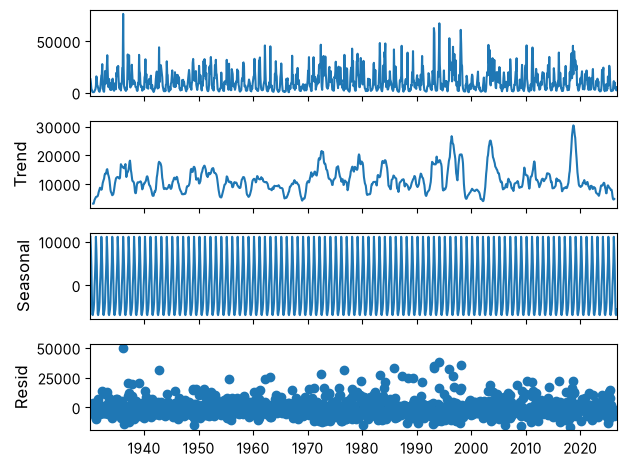

In [7]:
decomposed_ts = seasonal_decompose(monthly_df, model='additive', period=12)
decomposed_ts.plot()

In [8]:
trend_df = decomposed_ts.trend
seasonal_df = decomposed_ts.seasonal
resid_df = decomposed_ts.resid
resid_df.info()

<class 'pandas.Series'>
DatetimeIndex: 1160 entries, 1930-03-01 to 2026-10-01
Series name: resid
Non-Null Count  Dtype  
--------------  -----  
1148 non-null   float64
dtypes: float64(1)
memory usage: 18.1 KB


<Axes: title={'center': 'Flow residuals — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

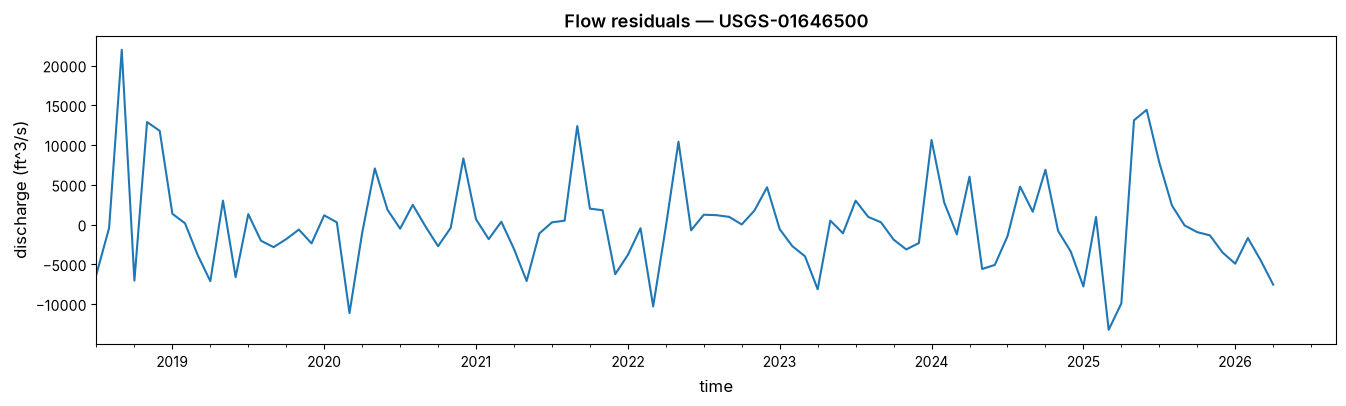

In [9]:
resid_df.iloc[-100:-1].plot(
    figsize=(16, 4),
    title="Flow residuals — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

In [10]:
rhis_resid = Rhis(resid_df.to_frame(name='Flow_resid'))
rhis_resid.numeric_orig_df.head(20)

,Flow_resid
time,
1930-03-01,NaN
1930-04-01,NaN
1930-05-01,NaN
1930-06-01,NaN
1930-07-01,NaN
1930-08-01,NaN
1930-09-01,3625.438160
1930-10-01,2877.273479
1930-11-01,743.057241


In [12]:
rhis_resid.numeric_orig_df.tail(20)

,Flow_resid
time,
2025-03-01,-13219.815802
2025-04-01,-9910.075209
2025-05-01,13123.684025
2025-06-01,14432.279370
2025-07-01,7813.361365
2025-08-01,2404.096867
2025-09-01,-103.862787
2025-10-01,-944.135622
2025-11-01,-1354.159477


In [13]:
start, end = rhis_resid.get_repr_idxs()['Flow_resid']
print(start, end)

0 0


In [44]:
p_evol_resid = rhis_resid.build_rhis_evol_dict()

In [47]:
evol_resid_df = build_rhis_evol_df(rhis_resid)
evol_resid_df.info()
evol_resid_df.head()

<class 'pandas.DataFrame'>
DatetimeIndex: 1160 entries, 1930-03-01 to 2026-10-01
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   (Flow_resid, R)         1147 non-null   float64
 1   (Flow_resid, H)         1147 non-null   float64
 2   (Flow_resid, I)         1147 non-null   float64
 3   (Flow_resid, S)         1147 non-null   float64
 4   (Flow_resid, RHIS-min)  1147 non-null   float64
dtypes: float64(5)
memory usage: 54.4 KB


series        Flow_resid                                               
hypothesis             R         H             I        S      RHIS-min
time                                                                   
1930-03-01  1.121325e-13  0.445256  8.047666e-08  0.92943  1.121325e-13
1930-04-01  1.121325e-13  0.445256  8.047666e-08  0.92943  1.121325e-13
1930-05-01  1.121325e-13  0.445256  8.047666e-08  0.92943  1.121325e-13
1930-06-01  1.121325e-13  0.445256  8.047666e-08  0.92943  1.121325e-13
1930-07-01  1.121325e-13  0.445256  8.047666e-08  0.92943  1.121325e-13

In [49]:
evol_resid_df.tail(20)

series     Flow_resid                                        
hypothesis          R         H         I         S  RHIS-min
time                                                         
2025-03-01   0.000682  0.201336  0.004742  0.079802  0.000682
2025-04-01   0.002121  0.038319  0.013622  0.006044  0.002121
2025-05-01   0.006438  0.005075  0.023531  0.000093  0.000093
2025-06-01   0.001749  0.008113  0.074246  0.000186  0.000186
2025-07-01   0.005729  0.012186  0.134056  0.000677  0.000677
2025-08-01   0.018321  0.037336  0.246545  0.002499  0.002499
2025-09-01   0.056530  0.060602  0.460995  0.009375  0.009375
2025-10-01        NaN       NaN       NaN       NaN       NaN
2025-11-01        NaN       NaN       NaN       NaN       NaN
2025-12-01        NaN       NaN       NaN       NaN       NaN
2026-01-01        NaN       NaN       NaN       NaN       NaN
2026-02-01        NaN       NaN       NaN       NaN       NaN
2026-03-01        NaN       NaN       NaN       NaN       NaN
2026-04-01        NaN       NaN       NaN       NaN       NaN
2026-05-01        NaN       NaN       NaN       NaN       NaN
2026-06-01        NaN       NaN       NaN       NaN       NaN
2026-07-01        NaN       NaN       NaN       NaN       NaN
2026-08-01        NaN       NaN       NaN       NaN       NaN
2026-09-01        NaN       NaN       NaN       NaN       NaN
2026-10-01        NaN       NaN       NaN       NaN       NaN

In [28]:
repr_resid_df = build_repr_df(rhis_resid)

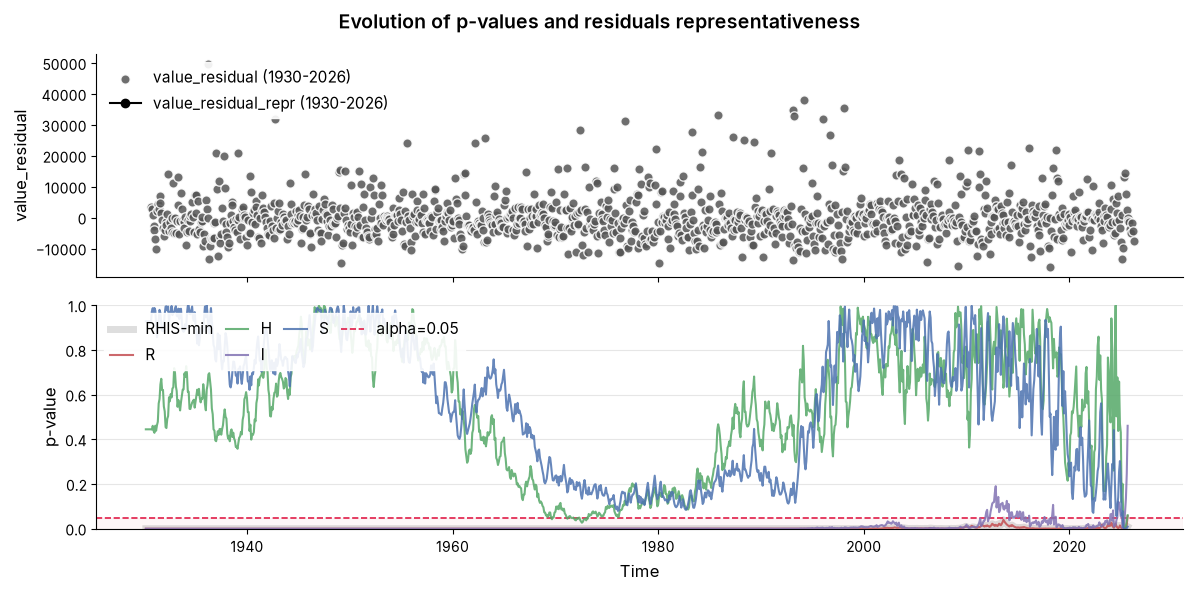

In [29]:
plot_rhis_evolution(
    rhis_resid.numeric_orig_df,
    evol_resid_df, 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_resid_df,
    figtitle='Evolution of p-values and residuals representativeness',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

## RHIS-compliant series from daily flows

In daily frequency, we can expect to have high persistence/dependence even in short slices of the series. So, the RHIS-compliant stretch should be a very short series due to rejection of independence hypothesis, or even there are no RHIS-compliant series, if the last test which is performed with the 8 most recent measurements rejects any of the hypothesis. This should take a little while given the size of the series. 

In [10]:
rhis = Rhis(target_df)
repr_idxs = rhis.get_repr_idxs() # Get the indexes that define the most recent RHIS-compliant stretch. It doesn't save the p-values

print(repr_idxs)

{'value': (0, 0)}


The method returned (0, 0), which means that there is no RHIS compliant stretch for this series.

## Let's look at the p-value evolutions

In [11]:
p_evol = rhis.build_rhis_evol_dict() # Save the p-value evolutions
rhis_df = build_rhis_evol_df(rhis) # Helper function to create a datafarme from the p-value evolutions
repr_df = build_repr_df(rhis) # Helper function to create a datafarme with the RHIS-compliant stretch, which is None in this case

In [14]:
start, stop = repr_idxs["value"]
print(start, stop)
# repr_df.iloc[start:stop].plot(
#     kind="line", figsize=(8, 4),
#     style="o",
#     linestyle="None",
#     title="RHIS-compliant Daily streamflow — USGS-01646500",
#     xlabel="time", ylabel="discharge (ft^3/s)",
# )

0 0


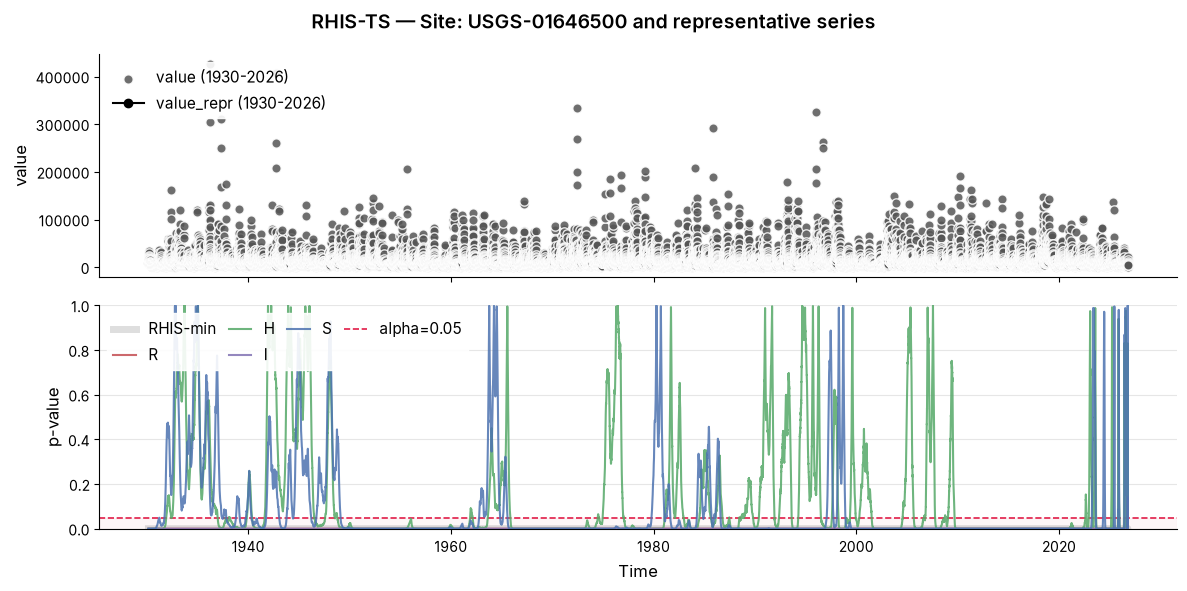

In [35]:
plot_rhis_evolution(
    rhis.numeric_orig_df,
    rhis_df, 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_df,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

The p-values start all below alpha level. Going towards the most recent, homogeneity and stationarity move above and below the rejection level many times, but randomness and independence continue being rejected until the last test, with the most recent minimum stretch (8 values).

## Looking closer (last 100 elements)

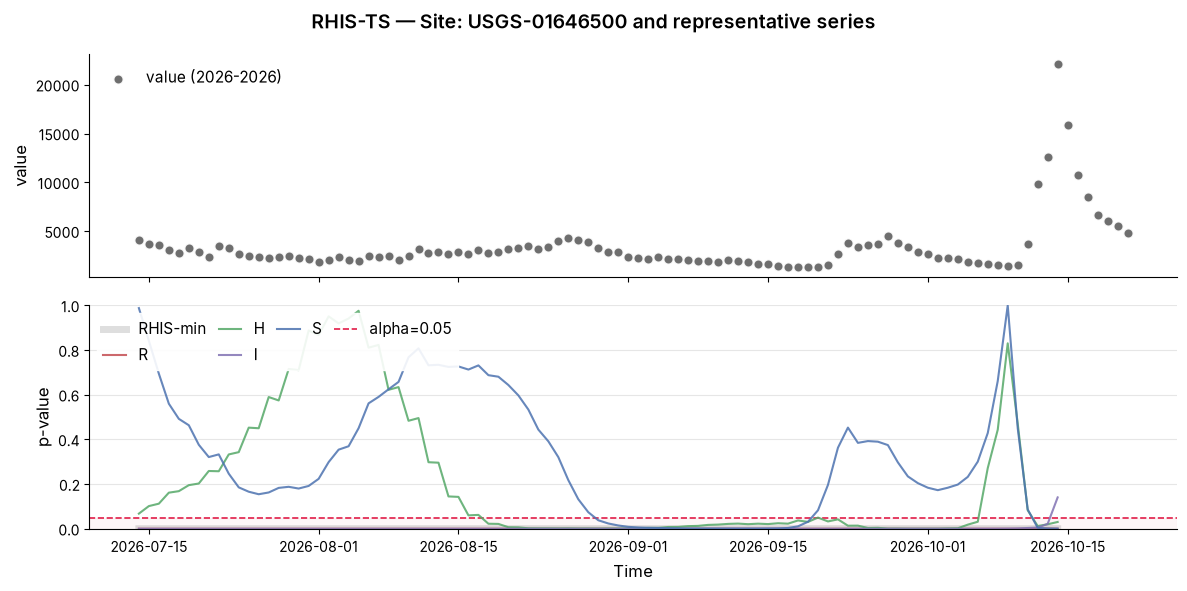

In [32]:
plot_rhis_evolution(
    rhis.numeric_orig_df.iloc[len(df) - 100:],
    rhis_df.iloc[len(df) - 100:], 0.05,
    show_repr=False,
    save=False,
    repr_df=None,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

Here we can see that randomness and independence keep being rejected until the last test with 8 most recent values, as well as homogeneity and stationarity. That's why rhis_ts resulted in no RHIS-compliant stretch.

# What about monthly scale?

We can expect less dependence between flows, but seasonality will still be present and should continue to cause several rejections of randomness and independence.

In [33]:
df_monthly = target_df.resample("MS").mean().reset_index().set_index('time')

<Axes: title={'center': 'Monthly streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

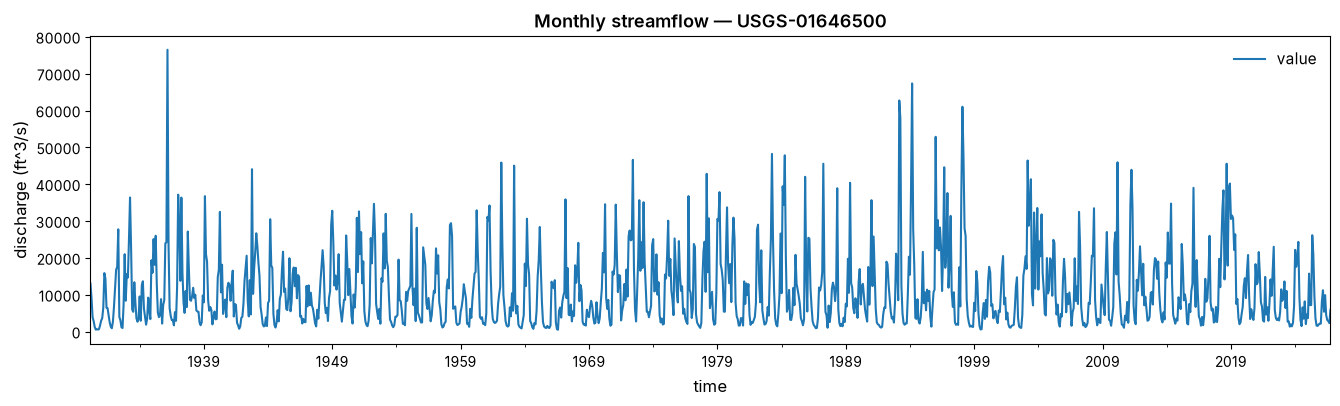

In [36]:
df_monthly.plot(
    figsize=(16, 4),
    title="Monthly streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

{'value': (1147, 1160)}


<Axes: title={'center': 'RHIS-compliant Monthly streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

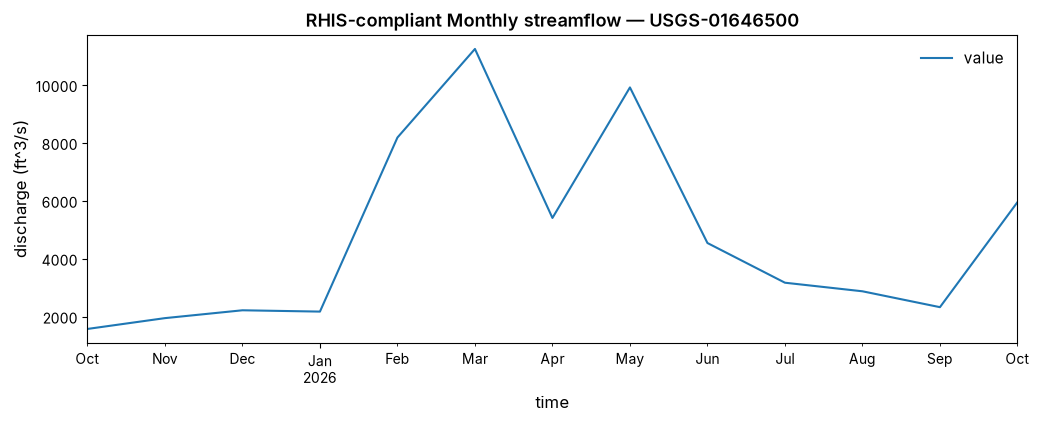

In [ ]:
rhis_m = Rhis(df_monthly)
repr_idxs_m = rhis_m.get_repr_idxs() # Get the indexes that define the most recent RHIS-compliant stretch. It doesn't save the p-values
print(repr_idxs_m)

p_evol = rhis_m.build_rhis_evol_dict() # Save the p-value evolutions
rhis_df_m = build_rhis_evol_df(rhis_m) # This is just a helper function to create a datafarme from the p-value evolutions
repr_df_m = build_repr_df(rhis_m) # This is just a helper function to create a datafarme from with the representative stretches from each time series

start, stop = repr_idxs_m["value"]
repr_df_m.iloc[start:stop].plot(
    figsize=(12, 4),
    title="RHIS-compliant Monthly streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

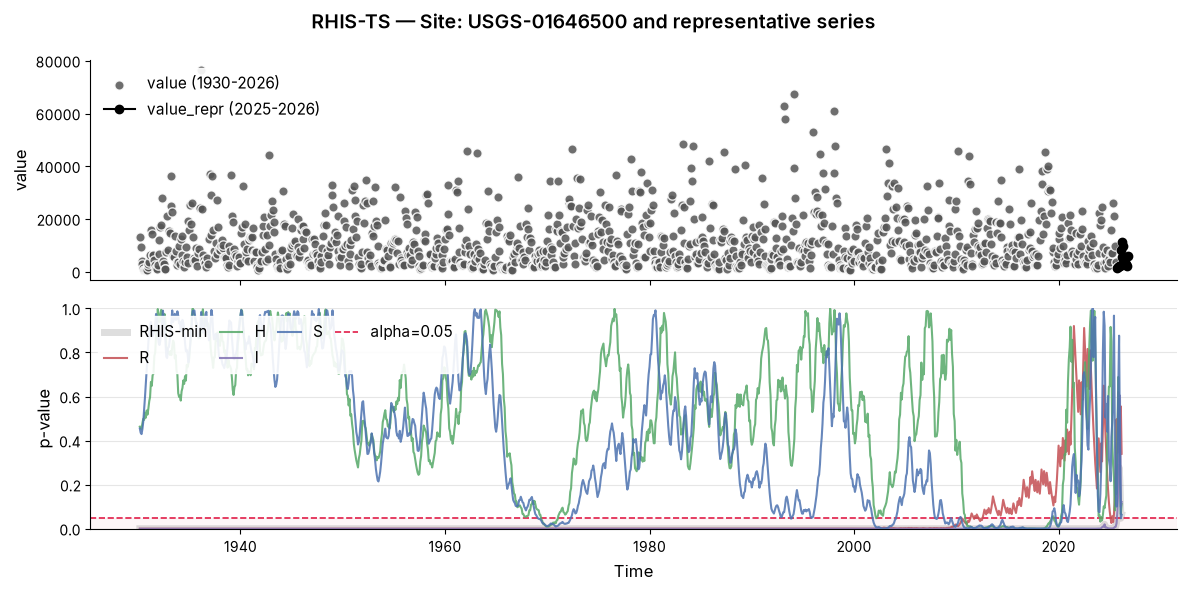

In [40]:
plot_rhis_evolution(
    rhis_m.numeric_orig_df,
    rhis_df_m, 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_df_m,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

Seasonality still has significant impact on dependence on the monthly scale. So, analyzing the series without any pre-treatment regarding seasons returns a very short RHIS-compliant series. Be careful here, we cannot say this stretch is representative, only that it does not provide enough evidence to reject the RHIS hypotheses, and looking at the full series we can see clearly that there is cyclic variations (seasonality). The right thing to do is separate the data into seasons.

## And annual flows?

In annual scale, we can see that the entire time series is RHIS-compliant, which means that the series doesn't provide enough evidence for the detection of any variability pattern.

### Rescale to annual frequency

<Axes: title={'center': 'Annual streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

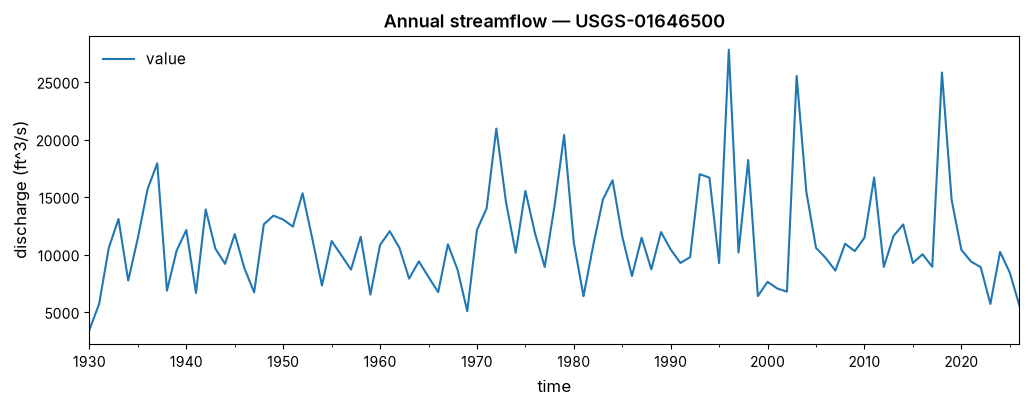

In [42]:
df_annual = target_df.resample("YS").mean().reset_index().set_index('time')

df_annual.plot(
    figsize=(12, 4),
    title="Annual streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

### Get representative indexes and build p-value evolutions

In [43]:
rhis_y = Rhis(df_annual)
repr_idxs_y = rhis_y.get_repr_idxs() # Get the indexes that define the most recent RHIS-compliant stretch. It doesn't save the p-values
print(repr_idxs_y)

p_evol = rhis_y.build_rhis_evol_dict() # Save the p-value evolutions
rhis_df_y = build_rhis_evol_df(rhis_y) # This is just a helper function to create a datafarme from the p-value evolutions
repr_df_y = build_repr_df(rhis_y) # This is just a helper function to create a datafarme from with the representative stretches from each time series

{'value': (0, 97)}


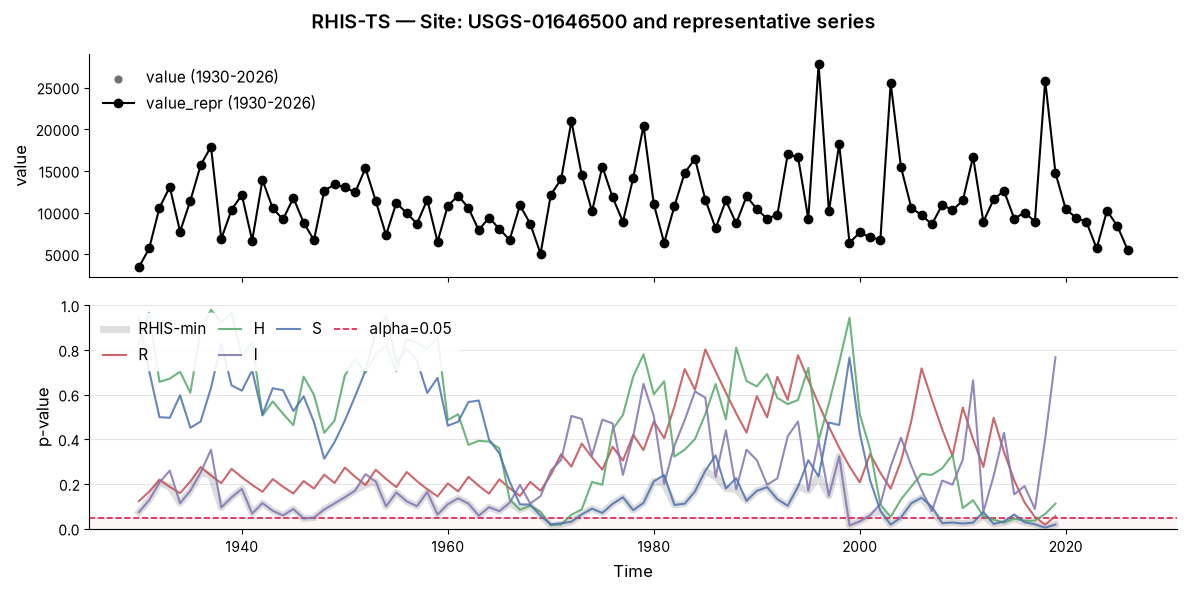

In [44]:
plot_rhis_evolution(
    rhis_y.numeric_orig_df,
    rhis_df_y, 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_df_y,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

## Let's decompose the series into trend, seasonal, and random components

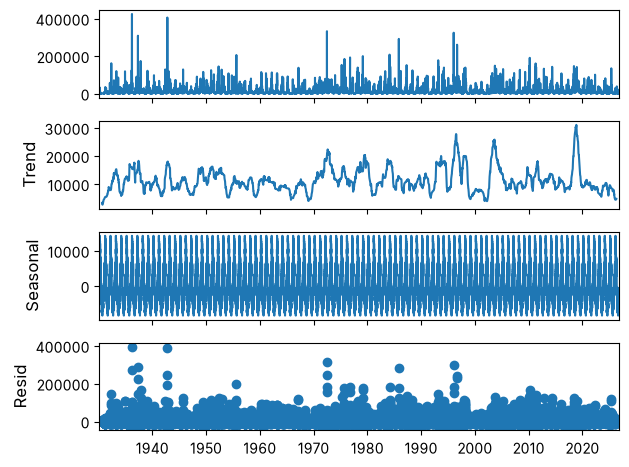

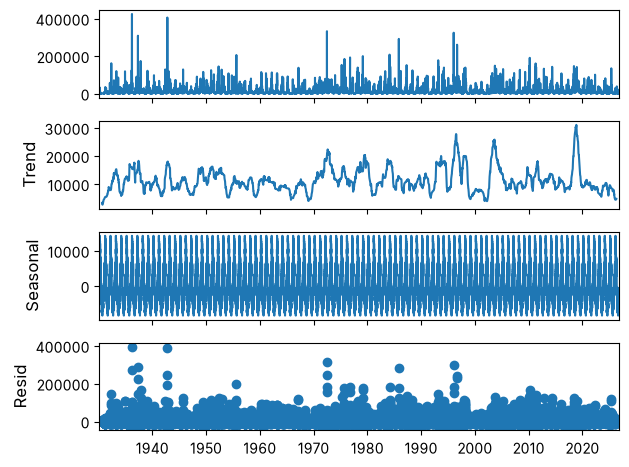

In [49]:
result.plot()

In [ ]:
resid = result.resid
resid.info()
rhis_resid = Rhis(resid.to_frame(name='value_residual'))
start, end = rhis_resid.get_repr_idxs()['value_residual']
p_evol_resid = rhis_resid.build_rhis_evol_dict()
rhis_resid_df = build_rhis_evol_df(rhis_resid)
repr_resid_df = build_repr_df(rhis_resid)
plot_rhis_evolution(
    rhis_resid.numeric_orig_df.iloc[len(df) - 500:],
    rhis_resid_df.iloc[len(df) - 500:], 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_resid_df,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

<class 'pandas.Series'>
DatetimeIndex: 35299 entries, 1930-03-01 to 2026-10-21
Series name: resid
Non-Null Count  Dtype  
--------------  -----  
34935 non-null  float64
dtypes: float64(1)
memory usage: 551.5 KB


In [59]:
print(start, end)

35107 35299


In [61]:
rhis_resid.numeric_orig_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 35299 entries, 1930-03-01 to 2026-10-21
Data columns (total 1 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   value_residual  34935 non-null  float64
dtypes: float64(1)
memory usage: 551.5 KB


In [56]:
p_evol_resid = rhis_resid.build_rhis_evol_dict()
rhis_resid_df = build_rhis_evol_df(rhis_resid)
repr_resid_df = build_repr_df(rhis_resid)


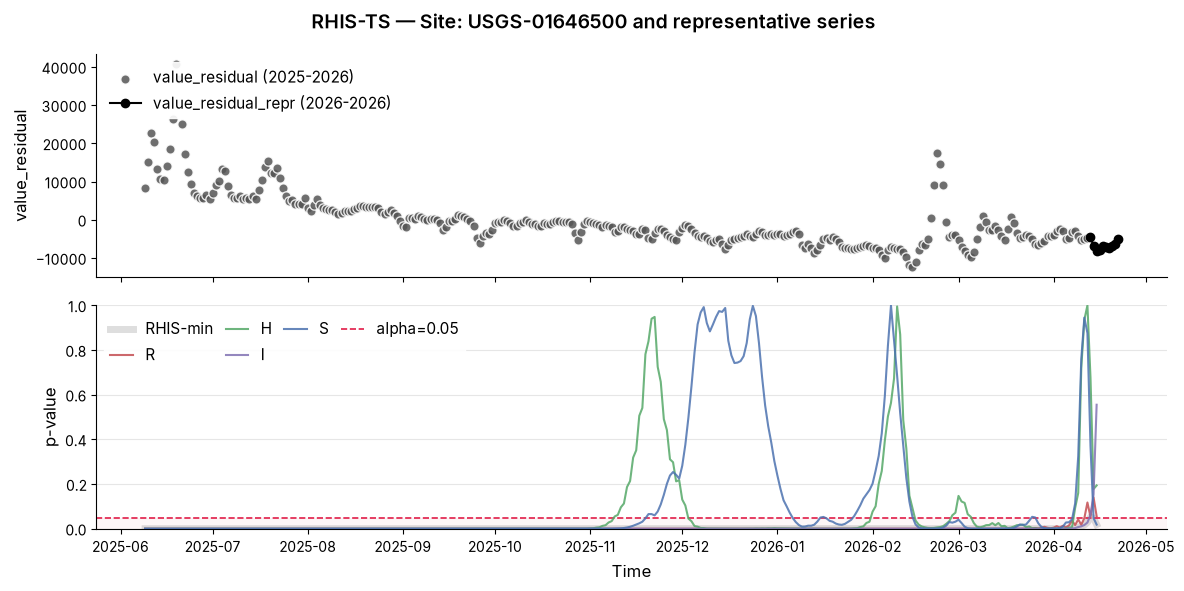

In [60]:
plot_rhis_evolution(
    rhis_resid.numeric_orig_df.iloc[len(df) - 500:],
    rhis_resid_df.iloc[len(df) - 500:], 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_resid_df,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )